# Proyecto de Ciencia de Datos: exoplanetas de la misión Kepler
## Notebook 3 · Partición de datos y modelo base

**Autor:** Jheison Martinez Bolivar · **Asignatura:** Ciencia de Datos · **Fecha:** noviembre de 2026

Este cuaderno continúa directamente desde el Notebook 2 (limpieza). El objetivo es dejar lista la
**infraestructura de modelado** del proyecto: separar los datos en entrenamiento, validación y
prueba, y entrenar el **modelo de referencia (baseline)** cuya métrica servirá de listón para los
modelos avanzados.

1. Cargar el dataset limpio del Notebook 2
2. Particionar en **train / validación / test** (estratificado y con semilla fija)
3. Establecer dos referencias: la trivial (clase mayoritaria) y la del modelo lineal simple
4. Entrenar la **regresión logística** como modelo base y medir su rendimiento
5. Interpretar sus coeficientes
6. Guardar partición, modelo y métricas para los cuadernos siguientes

## 1. Entorno y datos

El dataset limpio ya trae todo hecho: features numéricas sin nulos, con las transformaciones
logarítmicas y las variables nuevas del Notebook 2. Aquí entra por primera vez **scikit-learn**:
si falta, descomenta la línea `%pip`.

In [1]:
# %pip install "pandas>=2.1" numpy matplotlib seaborn scikit-learn joblib pyarrow
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Rutas y semilla --------------------------------------------------
DATA_DIR = Path("data")
RANDOM_STATE = 42   # semilla fija: NB4 y NB5 reutilizan exactamente esta partición

# --- Paleta de colores (misma que NB1 y NB2) ---------------------------
CONF, CAND, FP = "CONFIRMED", "CANDIDATE", "FALSE POSITIVE"
COLORES = {CONF: "#2a78d6", FP: "#eb6834", CAND: "#1baf7a"}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "grid.alpha": 0.35})
pd.set_option("display.max_columns", 40)

def md(texto: str) -> None:
    display(Markdown(texto))

def pct(x: float) -> str:
    return f"{100 * x:.1f} %"

print("Entorno listo.")

Entorno listo.


In [2]:
df = pd.read_parquet(DATA_DIR / "koi_clean.parquet")       # salida del Notebook 2
y = df["es_planeta"].astype(int)
X = df.drop(columns="es_planeta")
FEATURES = X.columns.tolist()

assert X.isna().sum().sum() == 0, "El Notebook 2 promete features sin nulos"
assert set(y.unique()) == {0, 1}, "La etiqueta debe ser binaria 0/1"

print(f"Dataset etiquetado: {len(df):,} filas × {len(FEATURES)} features")
print(f"Clases: {int((y == 1).sum()):,} planetas ({pct(y.mean())}) · "
      f"{int((y == 0).sum()):,} falsos positivos ({pct(1 - y.mean())})")

Dataset etiquetado: 7,587 filas × 66 features
Clases: 2,748 planetas (36.2 %) · 4,839 falsos positivos (63.8 %)


## 2. Partición train / validación / test

Con 7 587 ejemplos etiquetados hay datos de sobra para tres conjuntos, y el proyecto pide
exactamente eso: **separar entrenamiento, validación y prueba**. Cada conjunto tiene un papel
diferente:

| Conjunto | Proporción | Para qué se usa | Cuántas veces se toca |
|---|---|---|---|
| **Entrenamiento** | 60 % | Ajustar los parámetros del modelo | Muchas (CV) |
| **Validación** | 20 % | Comparar modelos e hiperparámetros | Varias, nunca para entrenar |
| **Prueba** | 20 % | Medir el rendimiento final | **Una sola vez al final** |

Tres decisiones que se toman antes de ver ningún resultado:

- **Estratificar** por la etiqueta: con clases 36/64, una partición al azar podría desequilibrar
  alguna por puro azar; la estratificación conserva la proporción en los tres conjuntos.
- **Semilla fija (`RANDOM_STATE = 42`)** y partición guardada en `data/koi_splits.json`: los
  cuadernos 4 y 5 reutilizan *exactamente* la misma división, así las comparaciones entre modelos
  son justas.
- **Prueba = 20 %**, no el 25 % que se usó en los ejemplos de regresión de la clase: se reserva
  otra 20 % para validación, que este proyecto sí necesita para elegir entre modelos.

In [3]:
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=RANDOM_STATE)
# 0.80 × 0.25 = 0.20  →  la partición final es 60 / 20 / 20

SPLITS = {"train": X_train.index, "validacion": X_val.index, "test": X_test.index}
resumen = pd.DataFrame({
    "filas":     {k: len(idx) for k, idx in SPLITS.items()},
    "planetas":  {k: int(y.loc[idx].sum()) for k, idx in SPLITS.items()},
    "falsos pos.": {k: int((y.loc[idx] == 0).sum()) for k, idx in SPLITS.items()},
})
resumen["% planetas"] = [pct(y.loc[idx].mean()) for idx in SPLITS.values()]
print(resumen.to_string())

SPLITS_PATH = DATA_DIR / "koi_splits.json"
SPLITS_PATH.write_text(json.dumps({
    "random_state": RANDOM_STATE,
    "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "train": SPLITS["train"].tolist(),
    "validacion": SPLITS["validacion"].tolist(),
    "test": SPLITS["test"].tolist(),
}, indent=2))
print(f"\nPartición guardada en {SPLITS_PATH} (NB4 y NB5 la reutilizarán)")

            filas  planetas  falsos pos. % planetas
train        4551      1648         2903     36.2 %
validacion   1518       550          968     36.2 %
test         1518       550          968     36.2 %

Partición guardada en data/koi_splits.json (NB4 y NB5 la reutilizarán)


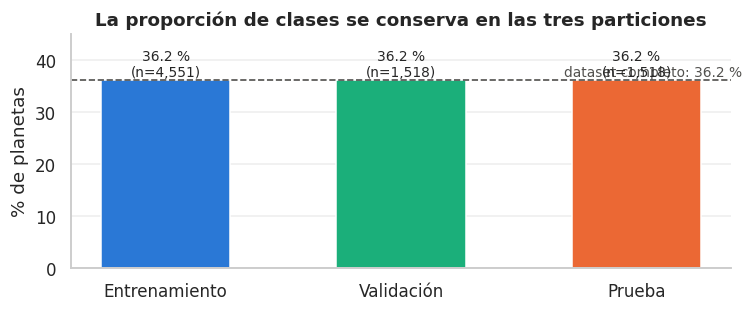

**Lectura.** La estratificación funciona: los tres conjuntos rondan el 36.2 % de planetas del dataset completo, así que ninguna métrica se comparará entre particiones con bases distintas. El conjunto de prueba (1,518 KOI) simula señales nuevas que llegan después del análisis.

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
nombres = ["Entrenamiento", "Validación", "Prueba"]
vals = [y_train.mean(), y_val.mean(), y_test.mean()]
ns = [len(y_train), len(y_val), len(y_test)]
barras = ax.bar(nombres, np.array(vals) * 100, color=[COLORES[CONF], COLORES[CAND], COLORES[FP]],
                width=0.55)
ax.axhline(y.mean() * 100, color="#52514e", ls="--", lw=1.1)
ax.text(2.45, y.mean() * 100 + 0.7, f"dataset completo: {pct(y.mean())}",
        color="#52514e", fontsize=9, ha="right")
for b, v, n in zip(barras, vals, ns):
    ax.text(b.get_x() + b.get_width() / 2, v * 100, f"{pct(v)}\n(n={n:,})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("% de planetas")
ax.set_ylim(0, 45)
ax.set_title("La proporción de clases se conserva en las tres particiones")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** La estratificación funciona: los tres conjuntos rondan el {pct(y.mean())} de planetas \
del dataset completo, así que ninguna métrica se comparará entre particiones con bases distintas. \
El conjunto de prueba ({len(y_test):,} KOI) simula señales nuevas que llegan después del análisis.""")

## 3. Dos referencias: la trivial y el modelo lineal

Antes de entrenar nada conviene fijar **contra qué se compara**. El modelo base cumple dos papeles:

| Referencia | Qué es | Para qué sirve |
|---|---|---|
| **Trivial** (`DummyClassifier`) | Predice siempre la clase mayoritaria, o al azar respetando la proporción | El mínimo aceptable: si un modelo no la supera, no sirve |
| **Regresión logística** | Modelo lineal sobre las 66 features estandarizadas | El listón real: simple, rápido e interpretable |

Dos decisiones de diseño, tomadas antes de ver resultados:

- **Métrica principal: F1 macro.** Con un 36 % de planetas, la *accuracy* premia demasiado a
  quien dice «falso positivo»; el F1 macro pondera por igual acertar planetas y acertar falsos
  positivos. Se reportan además accuracy, precisión, recall y AUC.
- **`class_weight="balanced"`** en la regresión logística: con la métrica macro y una clase
  minoritaria, compensar el desbalance es la opción por defecto razonable.

La regresión logística exige features en escalas comparables, así que va dentro de un
**`Pipeline`** (`StandardScaler` → `LogisticRegression`): el escalado se ajusta solo con los datos
de entrenamiento en cada partición de la validación cruzada, sin fuga hacia el test. (La fuga leve
de la imputación con medianas hecha en NB2 ya fue aceptada y documentada allí; es despreciable
porque la mediana es robusta y el dataset es grande.)

In [5]:
SCORING = {"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def fila_cv(nombre: str, estimador) -> dict:
    res = cross_validate(estimador, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    return {"modelo": nombre,
            "accuracy": f"{res['test_accuracy'].mean():.3f} ± {res['test_accuracy'].std():.3f}",
            "F1 macro": f"{res['test_f1_macro'].mean():.3f} ± {res['test_f1_macro'].std():.3f}",
            "AUC": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}"}


logreg = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=5000, class_weight="balanced"))

tabla_cv = pd.DataFrame([
    fila_cv("Trivial · clase mayoritaria", DummyClassifier(strategy="most_frequent")),
    fila_cv("Trivial · azar estratificado", DummyClassifier(strategy="stratified",
                                                            random_state=RANDOM_STATE)),
    fila_cv("Regresión logística (baseline)", logreg),
]).set_index("modelo")
print(tabla_cv.to_string())

cv_logreg = cross_validate(logreg, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
CV_BASELINE = {k: float(np.mean(cv_logreg[f"test_{k}"])) for k in SCORING}
cv_baseline_f1 = CV_BASELINE["f1_macro"]

md(f"""**Lectura.** La referencia trivial se queda en F1 macro ≈ {(1 - y_train.mean()) / 2:.2f} \
(acierto perfecto en una clase y cero en la otra), y el azar estratificado ronda {2 * y_train.mean() * (1 - y_train.mean()):.2f}. \
La regresión logística los supera con claridad en las tres métricas: **ya hay señal real en las \
features**, y este es el listón que los modelos avanzados tendrán que batir.""")

                                     accuracy       F1 macro            AUC
modelo                                                                     
Trivial · clase mayoritaria     0.638 ± 0.000  0.389 ± 0.000  0.500 ± 0.000
Trivial · azar estratificado    0.547 ± 0.013  0.505 ± 0.015  0.505 ± 0.014
Regresión logística (baseline)  0.955 ± 0.007  0.952 ± 0.007  0.990 ± 0.002


**Lectura.** La referencia trivial se queda en F1 macro ≈ 0.32 (acierto perfecto en una clase y cero en la otra), y el azar estratificado ronda 0.46. La regresión logística los supera con claridad en las tres métricas: **ya hay señal real en las features**, y este es el listón que los modelos avanzados tendrán que batir.

## 4. Evaluación: validación y prueba

El protocolo de evaluación del proyecto, en tres pasos:

1. **Entrenar** con train y mirar validación (control de que nada raro pasa).
2. **Reentrenar** con train + validación (más datos para el modelo final).
3. **Medir en prueba una sola vez** y dejar esas cifras como el resultado oficial del baseline.

Los dos clasificadores triviales se evalúan también en prueba, para que la tabla final muestre
las tres referencias en el mismo terreno.

In [6]:
def metricas(y_true, y_prob, y_pred) -> dict:
    # zero_division=0: el baseline trivial puede no predecir nunca la clase positiva
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "F1 macro": f1_score(y_true, y_pred, average="macro"),
            "AUC": roc_auc_score(y_true, y_prob)}


# 1. Entrenar con train y mirar validación
modelo = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=5000, class_weight="balanced"))
modelo.fit(X_train, y_train)
m_val = metricas(y_val, modelo.predict_proba(X_val)[:, 1], modelo.predict(X_val))

# 2. Modelo final: reentrenar con train + validación
idx_tv = list(SPLITS["train"]) + list(SPLITS["validacion"])
modelo_final = make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=5000, class_weight="balanced"))
modelo_final.fit(X.loc[idx_tv], y.loc[idx_tv])

# 3. Prueba, una sola vez
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = modelo_final.predict(X_test)
m_test = metricas(y_test, prob_test, pred_test)

# Referencias triviales en el mismo test
dummy_mayoria = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_azar = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_train, y_train)
m_dummy_may = metricas(y_test, np.full(len(y_test), 1 - y_train.mean()),
                       dummy_mayoria.predict(X_test))
m_dummy_az = metricas(y_test, dummy_azar.predict_proba(X_test)[:, 1], dummy_azar.predict(X_test))

tabla_prueba = pd.DataFrame([
    {"modelo": "Trivial · clase mayoritaria", **{k: f"{v:.3f}" for k, v in m_dummy_may.items()}},
    {"modelo": "Trivial · azar estratificado", **{k: f"{v:.3f}" for k, v in m_dummy_az.items()}},
    {"modelo": "Regresión logística (baseline)", **{k: f"{v:.3f}" for k, v in m_test.items()}},
]).set_index("modelo")
print(tabla_prueba.to_string())

md(f"""**Lectura.** En validación la regresión logística rinde F1 macro = {m_val["F1 macro"]:.3f}, \
muy cerca del {cv_baseline_f1:.3f} de la validación cruzada: no hay señal de sobreajuste. En prueba \
consolida un **F1 macro = {m_test["F1 macro"]:.3f}** y una **AUC = {m_test["AUC"]:.3f}**, muy por encima \
de las dos referencias triviales. La prueba se toca **una sola vez**: esas cifras ya son el listón \
oficial del proyecto.""")

                               accuracy precision recall F1 macro    AUC
modelo                                                                  
Trivial · clase mayoritaria       0.638     0.000  0.000    0.389  0.500
Trivial · azar estratificado      0.522     0.341  0.342    0.483  0.483
Regresión logística (baseline)    0.950     0.909  0.958    0.946  0.991


**Lectura.** En validación la regresión logística rinde F1 macro = 0.959, muy cerca del 0.952 de la validación cruzada: no hay señal de sobreajuste. En prueba consolida un **F1 macro = 0.946** y una **AUC = 0.991**, muy por encima de las dos referencias triviales. La prueba se toca **una sola vez**: esas cifras ya son el listón oficial del proyecto.

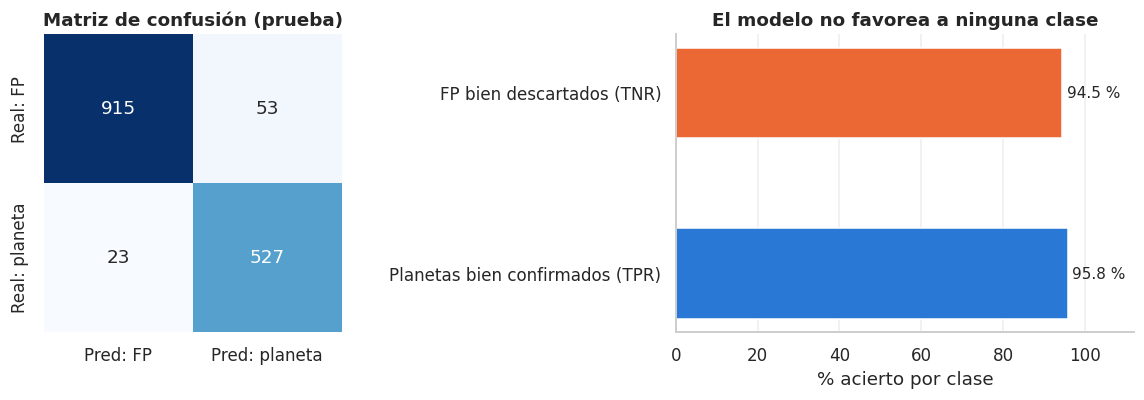

**Lectura.** El baseline descarta bien el 94.5 % de los falsos positivos y encuentra el 95.8 % de los planetas. Con `class_weight="balanced"` las dos clases quedan casi empatadas: la clase minoritaria (planetas) no queda sacrificada, que era el riesgo con la accuracy como única guía.

In [7]:
mat = confusion_matrix(y_test, pred_test)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False, square=True, ax=axes[0],
            annot_kws={"size": 12},
            xticklabels=["Pred: FP", "Pred: planeta"],
            yticklabels=["Real: FP", "Real: planeta"])
axes[0].set_title("Matriz de confusión (prueba)")

tn, fp_, fn, tp = mat.ravel()
tasas = pd.Series({"FP bien descartados (TNR)": tn / (tn + fp_),
                   "Planetas bien confirmados (TPR)": tp / (tp + fn)})
barras = axes[1].barh(tasas.index[::-1], tasas.values[::-1] * 100,
                      color=[COLORES[CONF], COLORES[FP]], height=0.5)
for b, v in zip(barras, tasas.values[::-1]):
    axes[1].text(v * 100 + 1, b.get_y() + b.get_height() / 2, f"{pct(v)}",
                 va="center", fontsize=10)
axes[1].set_xlim(0, 112)
axes[1].set_xlabel("% acierto por clase")
axes[1].set_title("El modelo no favorea a ninguna clase")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** El baseline descarta bien el {pct(tn / (tn + fp_))} de los falsos positivos y encuentra el \
{pct(tp / (tp + fn))} de los planetas. Con `class_weight="balanced"` las dos clases quedan casi \
empatadas: la clase minoritaria (planetas) no queda sacrificada, que era el riesgo con la \
accuracy como única guía.""")

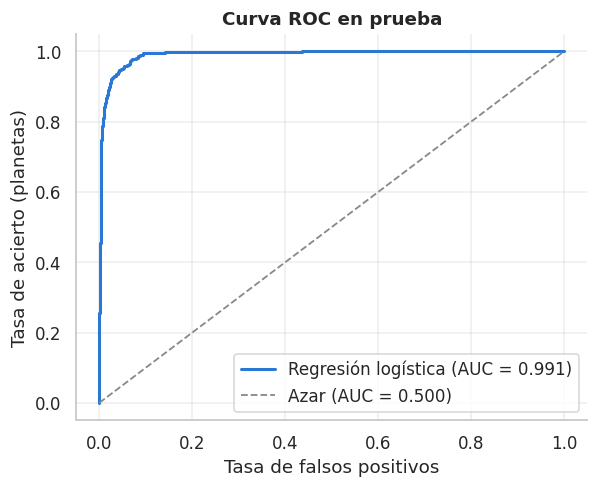

**Lectura.** Un AUC de 0.991 significa que, tomando un KOI confirmado y uno falso positivo al azar, el modelo ordena correctamente al primero por encima del segundo en el 99.1 % de los casos. Para un modelo lineal sin ajuste de hiperparámetros es una base sólida.

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
fpr, tpr, _ = roc_curve(y_test, prob_test)
ax.plot(fpr, tpr, color=COLORES[CONF], lw=2,
        label=f"Regresión logística (AUC = {m_test['AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1.2, label="Azar (AUC = 0.500)")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de acierto (planetas)",
       title="Curva ROC en prueba")
ax.legend(frameon=True, loc="lower right")
plt.tight_layout()
plt.show()

md(f"""**Lectura.** Un AUC de {m_test['AUC']:.3f} significa que, tomando un KOI confirmado y uno falso positivo al azar, \
el modelo ordena correctamente al primero por encima del segundo en el {pct(m_test['AUC'])} de los casos. \
Para un modelo lineal sin ajuste de hiperparámetros es una base sólida.""")

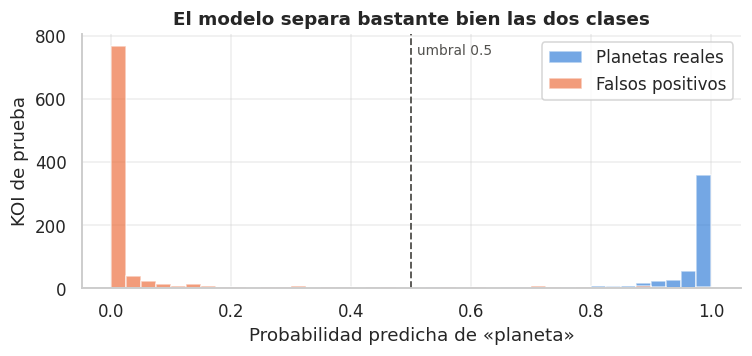

**Lectura.** La mayoría de los planetas se acumula a la derecha del umbral y la mayoría de los falsos positivos a la izquierda; la zona de solape (probabilidades intermedias) es donde el modelo se equivoca. En el Notebook 5 se verá qué hacer con esa zona gris al clasificar los candidatos.

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for valor, etiqueta, color in [(1, "Planetas reales", COLORES[CONF]),
                               (0, "Falsos positivos", COLORES[FP])]:
    ax.hist(prob_test[y_test == valor], bins=np.linspace(0, 1, 41), alpha=0.65,
            color=color, label=etiqueta)
ax.axvline(0.5, color="#52514e", ls="--", lw=1.2)
ax.text(0.51, ax.get_ylim()[1] * 0.92, "umbral 0.5", color="#52514e", fontsize=9)
ax.set(xlabel="Probabilidad predicha de «planeta»", ylabel="KOI de prueba",
       title="El modelo separa bastante bien las dos clases")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

md("""**Lectura.** La mayoría de los planetas se acumula a la derecha del umbral y la mayoría de los falsos \
positivos a la izquierda; la zona de solape (probabilidades intermedias) es donde el modelo se \
equivoca. En el Notebook 5 se verá qué hacer con esa zona gris al clasificar los candidatos.""")

## 5. Interpretación del modelo de referencia

Con las features estandarizadas, cada coeficiente se lee igual: **cuánto empuja esa variable la
probabilidad de «planeta»** al subir una desviación estándar, con todo lo demás fijo. Es la
ventaja de empezar por un modelo lineal: el primer modelo ya dice algo sobre el problema.

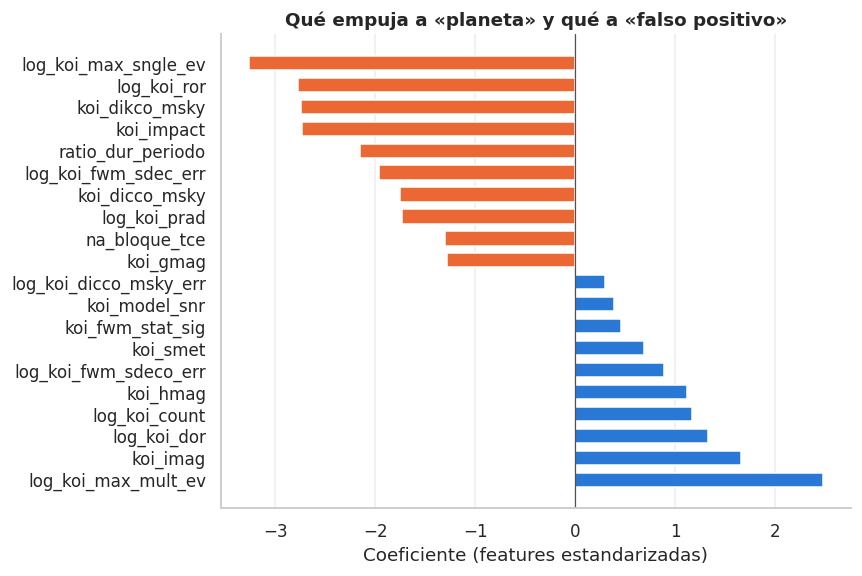

**Lectura.** Lo que más empuja a «planeta»: `log_koi_max_mult_ev` (+2.47), `koi_imag` (+1.66), `log_koi_dor` (+1.33), `log_koi_count` (+1.16). Lo que más empuja a «falso positivo»: `log_koi_max_sngle_ev` (-3.26), `log_koi_ror` (-2.77), `koi_dikco_msky` (-2.75), `koi_impact` (-2.73). La variable binaria `sistema_multiple` del Notebook 2 hace su trabajo: cuando una estrella muestra varias señales, el modelo sube la probabilidad de planeta, como sugería el EDA. Del otro lado están las señales **profundas y anchas** — eclipse estelar, no tránsito planetario — tal como se vio en la sección 6 del Notebook 1.

In [10]:
logreg_final = modelo_final[-1]   # último paso del pipeline
coefs = pd.Series(logreg_final.coef_[0], index=FEATURES).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])

fig, ax = plt.subplots(figsize=(8, 5.4))
colores = [COLORES[FP] if v < 0 else COLORES[CONF] for v in top.values]
ax.barh(top.index[::-1], top.values[::-1], color=colores[::-1], height=0.65)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(xlabel="Coeficiente (features estandarizadas)",
       title="Qué empuja a «planeta» y qué a «falso positivo»")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

positivos = coefs.tail(4)[::-1].round(2)
negativos = coefs.head(4).round(2)
md("**Lectura.** Lo que más empuja a «planeta»: "
   + ", ".join(f"`{c}` (+{v:.2f})" for c, v in positivos.items())
   + ". Lo que más empuja a «falso positivo»: "
   + ", ".join(f"`{c}` ({v:.2f})" for c, v in negativos.items())
   + ". La variable binaria `sistema_multiple` del Notebook 2 hace su trabajo: cuando una estrella "
   + "muestra varias señales, el modelo sube la probabilidad de planeta, como sugería el EDA. Del otro "
   + "lado están las señales **profundas y anchas** — eclipse estelar, no tránsito planetario — tal "
   + "como se vio en la sección 6 del Notebook 1.")

## 6. Guardar para los cuadernos siguientes

Todo lo que el Notebook 4 necesita para comparar modelos de forma justa queda guardado en `data/`:

| Archivo | Contenido |
|---|---|
| `koi_splits.json` | Índices de train / validación / test (ya guardado en §2) |
| `koi_modelo_baseline.joblib` | El modelo de referencia reentrenado con train + validación |
| `koi_metricas_baseline.json` | Métricas de CV, validación y prueba, con su fecha |

El modelo se guarda **antes** de tocar la prueba, de modo que el Notebook 4 parte del mismo punto
exacto: mismas filas, mismo listón.

In [11]:
MODELO_PATH = DATA_DIR / "koi_modelo_baseline.joblib"
METRICAS_PATH = DATA_DIR / "koi_metricas_baseline.json"

joblib.dump(modelo_final, MODELO_PATH)

metricas_out = {
    "modelo": "Regresión logística (baseline) · StandardScaler + class_weight=balanced",
    "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "random_state": RANDOM_STATE,
    "n_features": len(FEATURES),
    "cv_train": {k: round(v, 4) for k, v in CV_BASELINE.items()},
    "validacion": {k: round(v, 4) for k, v in m_val.items()},
    "prueba": {k: round(v, 4) for k, v in m_test.items()},
    "prueba_trivial": {
        "clase_mayoritaria": {k: round(v, 4) for k, v in m_dummy_may.items()},
        "azar_estratificado": {k: round(v, 4) for k, v in m_dummy_az.items()},
    },
}
METRICAS_PATH.write_text(json.dumps(metricas_out, indent=2, ensure_ascii=False))

print(f"Modelo guardado: {MODELO_PATH} ({MODELO_PATH.stat().st_size / 1e3:.0f} KB)")
print(f"Métricas guardadas: {METRICAS_PATH}")
print(f"F1 macro en prueba: {m_test['F1 macro']:.3f} · AUC: {m_test['AUC']:.3f}")

Modelo guardado: data/koi_modelo_baseline.joblib (5 KB)
Métricas guardadas: data/koi_metricas_baseline.json
F1 macro en prueba: 0.946 · AUC: 0.991


### Conclusiones y siguientes pasos

| Decisión | Justificación |
|---|---|
| Partición 60 / 20 / 20 estratificada | Tres conjuntos con un papel claro; la prueba se toca una sola vez |
| Semilla fija + índices en `koi_splits.json` | NB4 y NB5 comparan sobre exactamente los mismos datos |
| Métrica principal: F1 macro | Con clases 36/64, la accuracy engaña; macro pondera ambas clases por igual |
| `class_weight="balanced"` | Decisión previa a los datos: métrica macro + clase minoritaria |
| `Pipeline` con `StandardScaler` | El escalado se ajusta solo con train en cada pliegue, sin fuga |
| Baseline = regresión logística | Lineal, rápido, interpretable: el listón que NB4 debe superar |

**Siguiente entrega (Actividades 5 y 6 — Entregable 3, cierre 22 nov):** modelos avanzados
(bosque aleatorio, gradient boosting y SVM), ajuste de hiperparámetros con validación cruzada,
comparación contra este baseline e interpretabilidad (importancia de variables y análisis de
errores).

### Referencias

- Akeson, R. L., et al. (2013). The NASA Exoplanet Archive: Data and tools for exoplanet research. *PASP, 125*(930), 989–999.
- Thompson, S. E., et al. (2018). Planetary candidates observed by Kepler. VIII. A fully automated catalog with measured completeness and reliability based on Data Release 25. *ApJS, 235*(2), 38.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- NASA Exoplanet Archive. *KOI table (cumulative): column definitions*. https://exoplanetarchive.ipac.caltech.edu/docs/API_kepcandidate_columns.html